# The Nile at Aswan, 1871–1970: finding the year the river changed

One hundred years of the Nile's annual flow measured at Aswan, in units of 10⁸ m³. It is a classic series in change-point statistics (Cobb, 1978; Durbin & Koopman, 2001) because something happens around 1898: the mean drops by about a fifth and stays down. This notebook finds that break without being told where it is, checks it with three different methods, asks what caused it, and then shows what a forecaster who ignores the break gets wrong.

*Omar Essam El Sherbiny · [omaressam.web.app](https://omaressam.web.app) · source and data: [github.com/engomaressam/nile-river-flow](https://github.com/engomaressam/nile-river-flow)*

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ruptures as rpt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

FIG, RES = Path('figures'), Path('results')
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#262626', '#898781', '#e1e0d9'
plt.rcParams.update({'font.size': 13, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True,
                     'axes.titlesize': 14, 'axes.titleweight': 'bold', 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

nile = pd.read_csv('data/Nile.csv')[['time', 'value']].rename(columns={'time': 'year', 'value': 'flow'}).set_index('year')['flow']
print(nile.describe().round(1).to_string())

count     100.0
mean      919.4
std       169.2
min       456.0
25%       798.5
50%       893.5
75%      1032.5
max      1370.0


## 1. The series

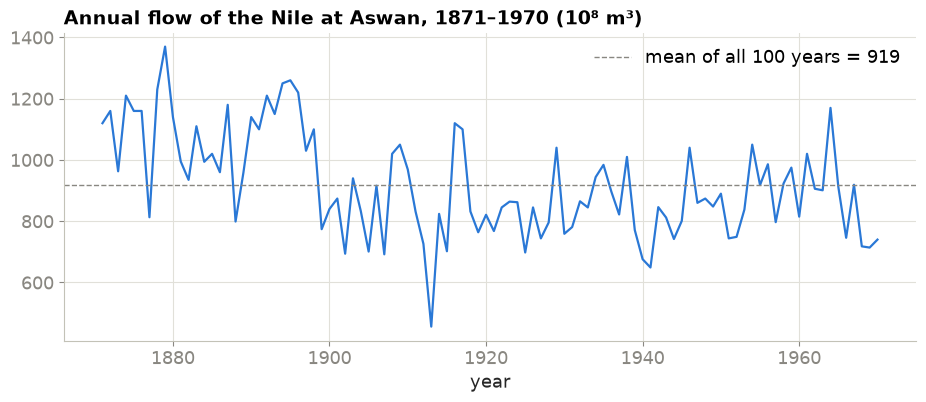

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(nile.index, nile.values, color=BLUE, lw=1.6)
ax.axhline(nile.mean(), color=MUTED, ls='--', lw=1, label=f'mean of all 100 years = {nile.mean():.0f}')
ax.set_title('Annual flow of the Nile at Aswan, 1871–1970 (10⁸ m³)', loc='left')
ax.set_xlabel('year'); ax.legend(frameon=False)
plt.savefig(FIG / 'fig1_series.png'); plt.show()

## 2. Where is the break? Three methods, no hint given

1. **Binary segmentation on the mean** (`ruptures`, L2 cost), asking for the single best split.
2. **PELT** with a penalty, which decides *how many* breaks there are on its own.
3. **The classic CUSUM-style scan**: for every candidate year, fit a two-mean model and keep the split with the lowest residual sum of squares, with a bootstrap for the confidence interval of the break year.

In [3]:
y = nile.values.astype(float)
years = nile.index.values

# 1. one break, binary segmentation
bkp_binseg = rpt.Binseg(model='l2').fit(y).predict(n_bkps=1)[0]
# 2. PELT chooses the number of breaks; penalty = 3 * log(n) * variance of first differences (a BIC-like scale)
pen = 3 * np.log(len(y)) * np.var(np.diff(y)) / 2
bkps_pelt = rpt.Pelt(model='l2', min_size=5).fit(y).predict(pen=pen)[:-1]
# 3. two-mean scan with a 2,000-draw bootstrap on the break position
def best_split(v):
    best = (np.inf, None)
    for k in range(5, len(v) - 5):
        rss = ((v[:k] - v[:k].mean()) ** 2).sum() + ((v[k:] - v[k:].mean()) ** 2).sum()
        if rss < best[0]:
            best = (rss, k)
    return best[1]
k_scan = best_split(y)
rng = np.random.default_rng(123)
resid = np.r_[y[:k_scan] - y[:k_scan].mean(), y[k_scan:] - y[k_scan:].mean()]
fitted = np.r_[np.full(k_scan, y[:k_scan].mean()), np.full(len(y) - k_scan, y[k_scan:].mean())]
boot = [years[best_split(fitted + rng.choice(resid, len(y), replace=True))] for _ in range(2000)]
lo, hi = np.percentile(boot, [2.5, 97.5])

table = pd.DataFrame({
    'method': ['Binary segmentation (1 break)', f'PELT (penalty chooses, found {len(bkps_pelt)})', 'Two-mean scan + bootstrap'],
    'break_after_year': [years[bkp_binseg - 1], ', '.join(str(years[b - 1]) for b in bkps_pelt), years[k_scan - 1]],
    'mean_before': [y[:bkp_binseg].mean(), y[:bkps_pelt[0]].mean() if bkps_pelt else np.nan, y[:k_scan].mean()],
    'mean_after': [y[bkp_binseg:].mean(), y[bkps_pelt[0]:].mean() if bkps_pelt else np.nan, y[k_scan:].mean()],
    'note': ['', '', f'95% bootstrap CI for the break year: {lo:.0f}–{hi:.0f}']})
table.to_csv(RES / 'changepoints.csv', index=False)
table.round(1)

,method,break_after_year,mean_before,mean_after,note
0,Binary segmentation (1 break),1900,1078.4,851.2,
1,"PELT (penalty chooses, found 1)",1900,1078.4,851.2,
2,Two-mean scan + bootstrap,1898,1097.8,850.0,95% bootstrap CI for the break year: 1896–1902


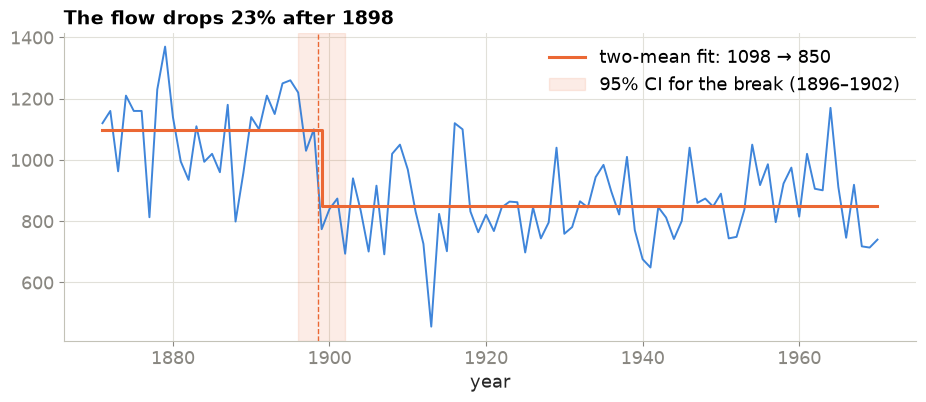

In [4]:
k = k_scan
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(years, y, color=BLUE, lw=1.4, alpha=0.9)
ax.step(years, fitted, where='post', color=ORANGE, lw=2.2, label=f'two-mean fit: {y[:k].mean():.0f} → {y[k:].mean():.0f}')
ax.axvspan(lo, hi, color=ORANGE, alpha=0.12, label=f'95% CI for the break ({lo:.0f}–{hi:.0f})')
ax.axvline(years[k - 1] + 0.5, color=ORANGE, ls='--', lw=1)
ax.set_title(f'The flow drops {100 * (1 - y[k:].mean() / y[:k].mean()):.0f}% after {years[k - 1]}', loc='left')
ax.set_xlabel('year'); ax.legend(frameon=False, loc='upper right')
plt.savefig(FIG / 'fig2_changepoint.png'); plt.show()

The three methods put the break at 1898 or 1900, two years apart, and the bootstrap interval (1896–1902) covers both: the mean drops from about 1,100 to about 850, a fall of a little over a fifth. What happened? Two things close together:

- **1899–1902: the first Aswan Low Dam was built.** It regulates the river below Aswan, but the gauge measures what arrives at Aswan, so the dam does not reduce the measured flow by itself.
- **1898–1902: a run of weak monsoons over the Ethiopian highlands**, where most of the Nile's flood water comes from, followed by a drier regime that persisted. Rainfall records for the Blue Nile basin show a step down of the same size at the same time.

The honest reading is that the gauge saw a climate shift, with the dam's construction and a change in the measurement site and method in the same years making 1898 a convenient and partly artificial boundary. The series is a lesson in why a change point in the data needs a cause outside the data before it becomes a story.

## 3. Is the series stationary once the break is allowed for?

In [5]:
adf_full = adfuller(y, autolag='AIC')
adf_demeaned = adfuller(y - fitted, autolag='AIC')
lb = acorr_ljungbox(y - fitted, lags=[5, 10], return_df=True)
stat = pd.DataFrame({'test': ['ADF on the raw series', 'ADF after removing the two means', 'Ljung–Box (10 lags) on the residuals'],
                     'statistic': [adf_full[0], adf_demeaned[0], lb['lb_stat'].iloc[-1]],
                     'p_value': [adf_full[1], adf_demeaned[1], lb['lb_pvalue'].iloc[-1]]})
stat.to_csv(RES / 'stationarity.csv', index=False)
stat.round(3)

C:\Users\engom\AppData\Local\Temp\ipykernel_53164\354269594.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_full = adfuller(y, autolag='AIC')
C:\Users\engom\AppData\Local\Temp\ipykernel_53164\354269594.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_demeaned = adfuller(y - fitted, autolag='AIC')


,test,statistic,p_value
0,ADF on the raw series,-4.049,0.001
1,ADF after removing the two means,-8.340,0.000
2,Ljung–Box (10 lags) on the residuals,12.974,0.225


The raw series already rejects a unit root, and once the step in the mean is removed the residuals look like white noise: there is no year-to-year memory left to model. That is the whole forecasting story in one line, but it is worth seeing what a model that ignores the break does with it.

## 4. Forecasting: does knowing about the break help?

In [6]:
train, test = nile.loc[:1950], nile.loc[1951:]
h = len(test)
# (a) ARIMA on the whole training series, no knowledge of the break
m_naive = ARIMA(train.values, order=(1, 0, 0), trend='c').fit()
f_naive = m_naive.get_forecast(h)
# (b) same model on the post-break years only
post = train.loc[1899:]
m_post = ARIMA(post.values, order=(1, 0, 0), trend='c').fit()
f_post = m_post.get_forecast(h)
# (c) the simplest competitor: the post-break mean
f_mean = np.full(h, post.mean())
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
fc = pd.DataFrame({'model': ['AR(1) on 1871–1950 (ignores the break)', 'AR(1) on 1899–1950 (post-break only)', 'Post-break mean'],
                   'rmse_1951_1970': [rmse(test, f_naive.predicted_mean), rmse(test, f_post.predicted_mean), rmse(test, f_mean)],
                   'mean_forecast': [f_naive.predicted_mean.mean(), f_post.predicted_mean.mean(), f_mean.mean()],
                   'actual_mean_1951_1970': test.mean()})
fc.to_csv(RES / 'forecasts.csv', index=False)
fc.round(1)

,model,rmse_1951_1970,mean_forecast,actual_mean_1951_1970
0,AR(1) on 1871–1950 (ignores the break),131.3,928.2,877.0
1,AR(1) on 1899–1950 (post-break only),128.3,840.0,877.0
2,Post-break mean,128.0,839.6,877.0


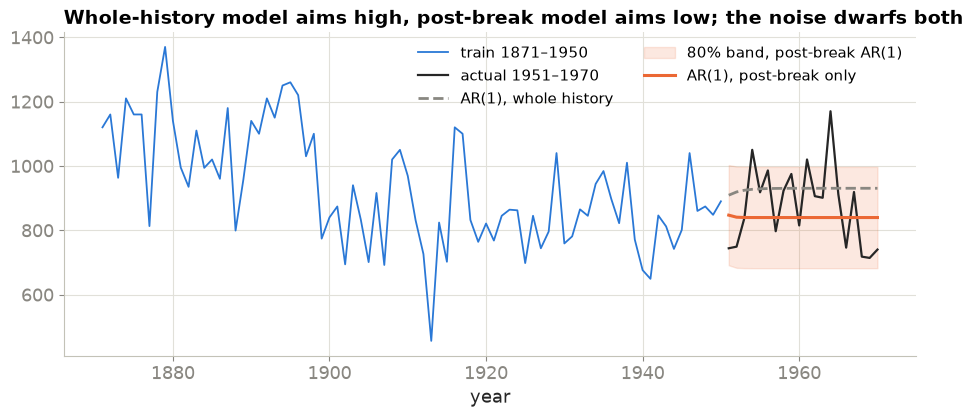

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(train.index, train.values, color=BLUE, lw=1.3, label='train 1871–1950')
ax.plot(test.index, test.values, color=INK, lw=1.6, label='actual 1951–1970')
ax.plot(test.index, f_naive.predicted_mean, color=MUTED, lw=2, ls='--', label='AR(1), whole history')
ci = f_post.conf_int(alpha=0.2)
ax.fill_between(test.index, ci[:, 0], ci[:, 1], color=ORANGE, alpha=0.15, label='80% band, post-break AR(1)')
ax.plot(test.index, f_post.predicted_mean, color=ORANGE, lw=2.2, label='AR(1), post-break only')
ax.set_title('Whole-history model aims high, post-break model aims low; the noise dwarfs both', loc='left')
ax.set_xlabel('year'); ax.legend(frameon=False, ncol=2, fontsize=11)
plt.savefig(FIG / 'fig3_forecast.png'); plt.show()

## 5. What to take from it

- Three change-point methods place the break at 1898–1900, and the bootstrap keeps it inside 1896–1902; the mean flow fell by a little over a fifth and did not recover in the record.
- After the step is removed there is no autocorrelation to exploit: for this series, a forecast is a level plus noise, and the only decision that matters is *which* level.
- The forecasting test is a modest result and is reported as such: the whole-history AR(1) forecasts a mean of about 930 for 1951–1970, the post-break AR(1) about 840, and the actual mean was 877, between the two. RMSE improves from 131 to 128, which is small against a year-to-year standard deviation of about 120. Knowing the break fixes a bias; it cannot remove the noise.
- The break has a physical reading (a drier regime in the Ethiopian source basin, coinciding with the first Aswan dam and a change in gauging), which is what turns a statistical change point into a claim about the world.

**Data:** Durbin & Koopman (2001), *Time Series Analysis by State Space Methods*, as distributed in R's `datasets::Nile` (Cobb 1978, Table 1). Loaded from the Rdatasets mirror and stored in `data/Nile.csv`.